In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json

df = pd.read_csv('dataset/creditcard.csv')
print(df.shape)          # harus (284807, 31)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Missing value: 0
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


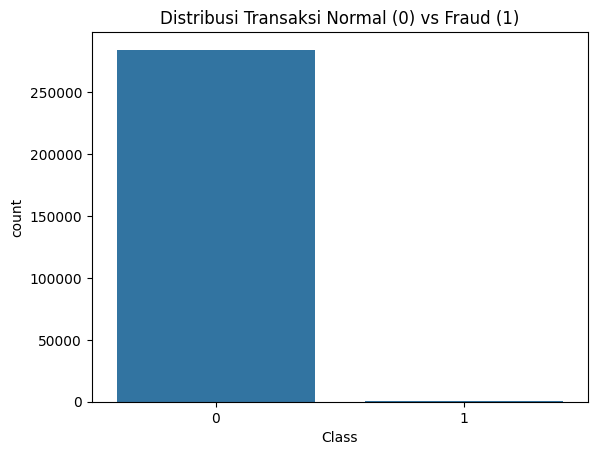

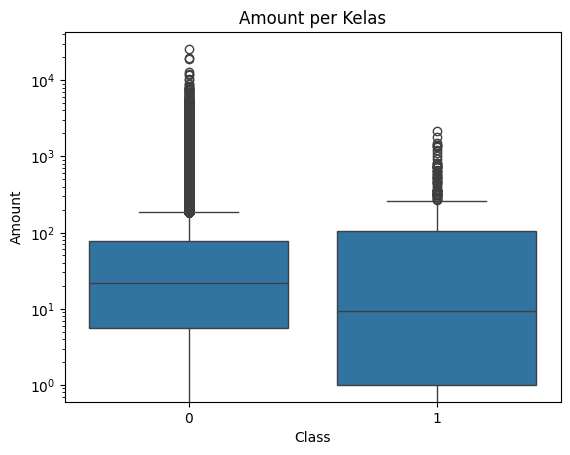

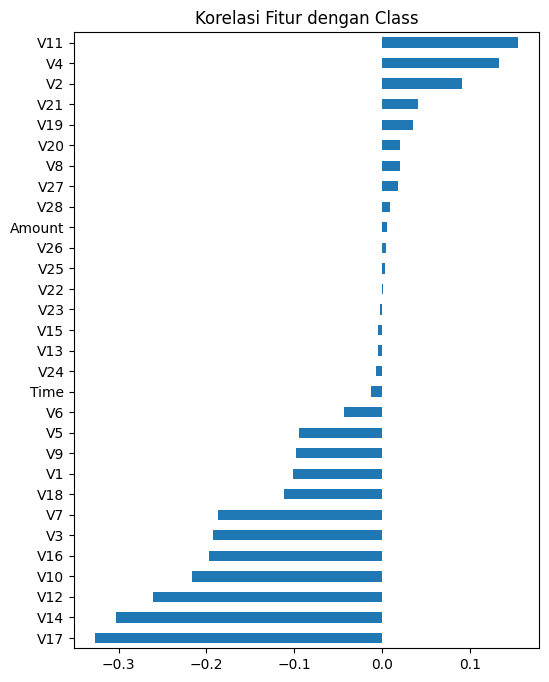

In [2]:
print("Missing value:", df.isnull().sum().sum())
print(df['Class'].value_counts())
print(df['Class'].value_counts(normalize=True) * 100)

sns.countplot(x='Class', data=df)
plt.title('Distribusi Transaksi Normal (0) vs Fraud (1)')
plt.show()

sns.boxplot(x='Class', y='Amount', data=df)
plt.yscale('log')
plt.title('Amount per Kelas')
plt.show()

df.corr()['Class'].drop('Class').sort_values().plot(kind='barh', figsize=(6, 8))
plt.title('Korelasi Fitur dengan Class')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_test_raw = X_test.copy()   

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
from imblearn.over_sampling import SMOTE

X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Sebelum:", y_train.value_counts().to_dict())
print("Sesudah:", pd.Series(y_train_sm).value_counts().to_dict())

Sebelum: {0: 227451, 1: 394}
Sesudah: {0: 227451, 1: 227451}


In [5]:
from sklearn.linear_model import LogisticRegression

model_a = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
model_b = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_sm, y_train_sm)
model_c = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42).fit(X_train, y_train)


===== Baseline =====
              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     56864
           1     0.8267    0.6327    0.7168        98

    accuracy                         0.9991     56962
   macro avg     0.9130    0.8162    0.8582     56962
weighted avg     0.9991    0.9991    0.9991     56962

AUC   : 0.9605
PR-AUC: 0.7414


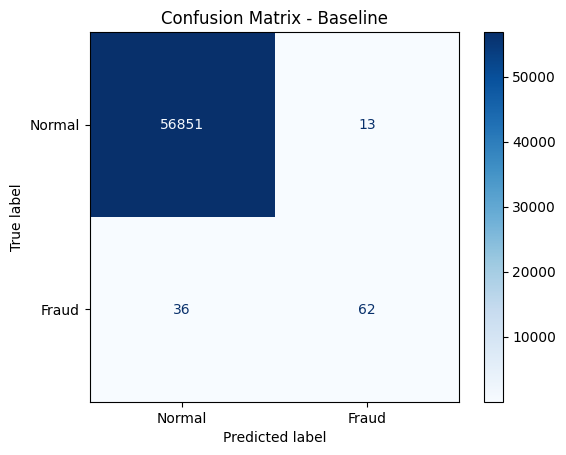


===== SMOTE =====
              precision    recall  f1-score   support

           0     0.9999    0.9742    0.9869     56864
           1     0.0578    0.9184    0.1088        98

    accuracy                         0.9741     56962
   macro avg     0.5288    0.9463    0.5478     56962
weighted avg     0.9982    0.9741    0.9854     56962

AUC   : 0.9708
PR-AUC: 0.7245


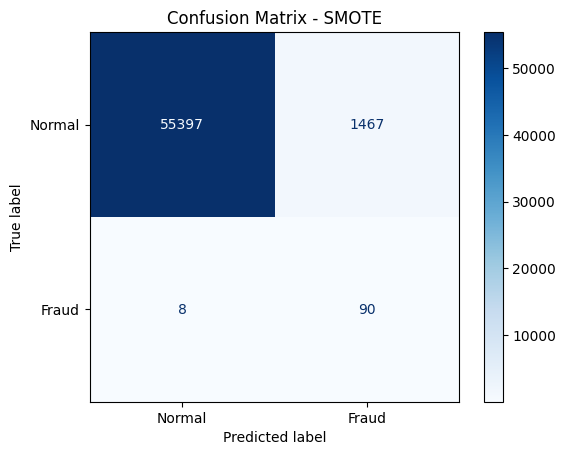


===== Class Weight =====
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962

AUC   : 0.9721
PR-AUC: 0.719


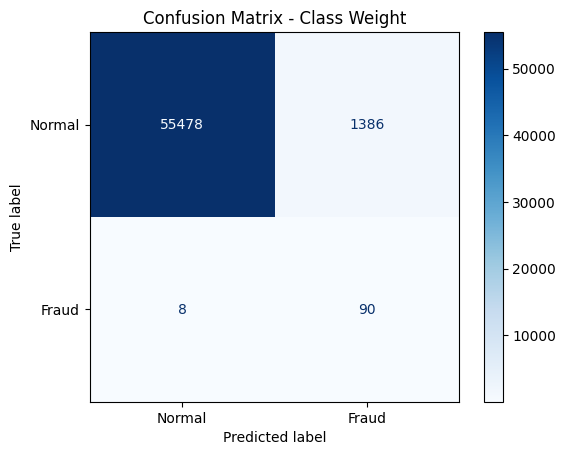

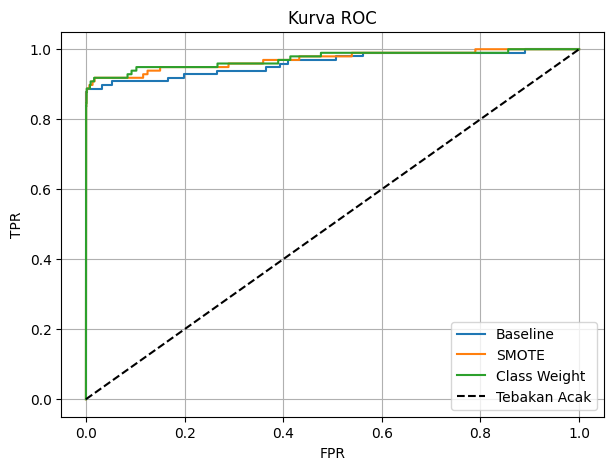

In [6]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, roc_curve)

def evaluasi(model, nama):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(f"\n===== {nama} =====")
    print(classification_report(y_test, pred, digits=4))
    print("AUC   :", round(roc_auc_score(y_test, proba), 4))
    print("PR-AUC:", round(average_precision_score(y_test, proba), 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=['Normal', 'Fraud']).plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {nama}')
    plt.show()

evaluasi(model_a, 'Baseline')
evaluasi(model_b, 'SMOTE')
evaluasi(model_c, 'Class Weight')

# ROC ketiga model
plt.figure(figsize=(7, 5))
for m, n in [(model_a, 'Baseline'), (model_b, 'SMOTE'), (model_c, 'Class Weight')]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=n)
plt.plot([0, 1], [0, 1], 'k--', label='Tebakan Acak')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.grid(True)
plt.title('Kurva ROC')
plt.show()

In [7]:
model_final = model_b   # ganti jika model lain lebih baik menurut Recall/F1/PR-AUC

joblib.dump(model_final, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'columns.pkl')

# Contoh transaksi untuk tombol "isi contoh" di aplikasi
proba = model_final.predict_proba(X_test)[:, 1]
idx_fraud = X_test_raw[(y_test == 1).values].index[np.argmax(proba[(y_test == 1).values])]
idx_normal = X_test_raw[(y_test == 0).values].index[0]
contoh = {
    'fraud': X_test_raw.loc[idx_fraud].to_dict(),
    'normal': X_test_raw.loc[idx_normal].to_dict(),
}
json.dump(contoh, open('contoh.json', 'w'))